# Week 11 - Introduction to Modeling, part 2

# 1. Lesson - No lesson this week

# 2. Weekly graph question

In [6]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer

The book names one of Vonnegut's rules as "keep it simple" and another as "have the guts to cut."  Here is some data from the previous week's lesson.  If you had to cut one of the two plots below, which would it be?  Which seems more interesting or important?  Explain.  (Should "amount of training data used" or "number of estimators" be on the x-axis.)

In [2]:
np.random.seed(0)
num_points = 10000
feature_1a = np.random.random(size = num_points) * 3
feature_2a = np.random.random(size = num_points) * 3
feature_3a = np.random.random(size = num_points) * 3
train_target = (feature_1a - 2 * feature_2a) * feature_3a + np.random.normal(size = num_points)
feature_1b = np.random.random(size = num_points) * 3
feature_2b = np.random.random(size = num_points) * 3
feature_3b = np.random.random(size = num_points) * 3
test_target = (feature_1b - 2 * feature_2b) * feature_3b + np.random.normal(size = num_points)
train_df = pd.DataFrame({"f1": feature_1a, "f2": feature_2a, "f3": feature_3a})
test_df = pd.DataFrame({"f1": feature_1b, "f2": feature_2b, "f3": feature_3b})
rf = RandomForestRegressor()
rf.fit(train_df.values, train_target)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [3]:
rmse_lst = list()
rf = RandomForestRegressor()
for x in range(round(num_points / 20), num_points, round(num_points / 20)):
    rf.fit(train_df.values[0:x,:], train_target[0:x])
    rmse_lst.append(root_mean_squared_error(rf.predict(test_df.values), test_target))

import matplotlib.pyplot as plt

Text(0, 0.5, 'Loss function')

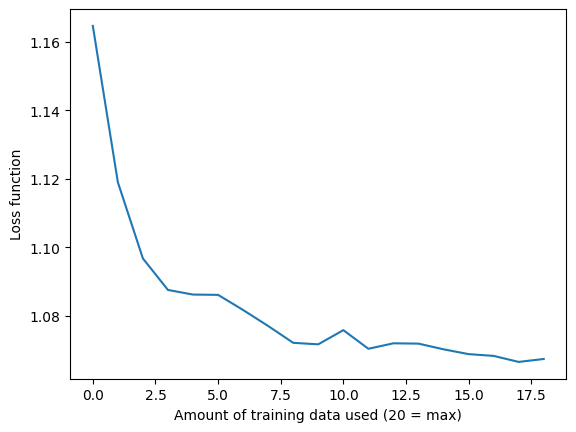

In [4]:
plt.plot(rmse_lst)
plt.xlabel("Amount of training data used (20 = max)")
plt.ylabel("Loss function")

In [5]:
num_trees_lst = list()
for n_estimators in range(1, 100, 3):
    rf = RandomForestRegressor(n_estimators = n_estimators)
    rf.fit(train_df.values, train_target)
    num_trees_lst.append(root_mean_squared_error(rf.predict(test_df.values), test_target))

Text(0, 0.5, 'Loss function')

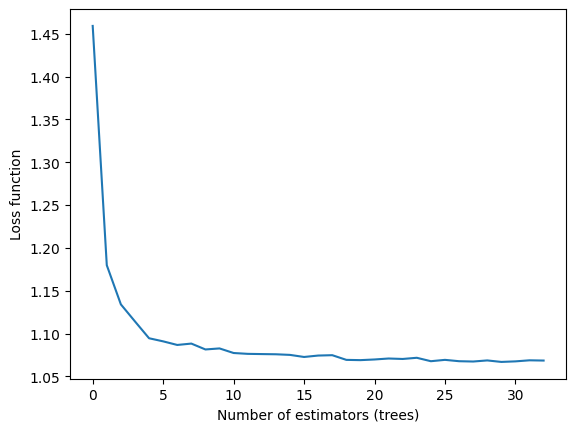

In [6]:
plt.plot(num_trees_lst)
plt.xlabel("Number of estimators (trees)")
plt.ylabel("Loss function")

In [ ]:
#Comparing the Two Plots

"""
I would cut the amount of training data used plot. The reason for cutting that plot is because the number of estimators (trees) plot is more useful as it clearly shows that the loss decresasesquickly as more trees are added. However, after 10-15 trees, adding more trees shows very little, if at all, any improvement. The training data plot shows that using more data lowers the loss, but it does not clearly show how much data is best to use.
"""

# 3. Working on your chosen project datasets this semester

This week, you will do the same types of exercises as last week, but you should use your chosen datasets that someone in your class found last semester. (They likely will not be the particular datasets that you found yourself.)

Here are some types of analysis you can do:

* Implement a random forest model.
* Perform cross-validation.
* Tune hyperparameters.
* Evaluate a performance metric.

If you like, you can try other types of models, too (beyond linear regression and random forest) although you will have many opportunities to do that next semester.

BRFSS Dataset

In [26]:
#Imports
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (train_test_split, cross_val_score, GridSearchCV)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix)

In [27]:
#BRFSS Random Forest Dataset

brfss_path = r"C:\Users\dmerce1\OneDrive - UHG\BU MS Data Science\DX699 - AI for Leader pt. 2\AI_Leaders\BRFSS.csv"

df_brfss = pd.read_csv(brfss_path)

print("BRFSS Dataset Shape:")
print(df_brfss.shape)

df_brfss.head()

BRFSS Dataset Shape:
(337894, 301)


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,_LCSCTSN,_LCSPSTF,DRNKANY6,DROCDY4_,_RFBING6,_DRNKWK3,_RFDRHV9,_FLSHOT7,_PNEUMO3,_AIDTST4
0,1,2,2282024,2,28,2024,1100,2024000001,2024000001,1,...,0.0,9.0,2.0,0.0,1.0,0.0,1.0,1.0,2.0,2.0
1,1,2,2212024,2,21,2024,1100,2024000002,2024000002,1,...,4.0,9.0,2.0,0.0,1.0,0.0,1.0,1.0,1.0,2.0
2,1,2,2212024,2,21,2024,1100,2024000003,2024000003,1,...,4.0,2.0,1.0,100.0,2.0,1400.0,1.0,0.0,0.0,2.0
3,1,2,2282024,2,28,2024,1100,2024000004,2024000004,1,...,0.0,9.0,2.0,0.0,1.0,0.0,1.0,1.0,1.0,2.0
4,1,2,2212024,2,21,2024,1100,2024000005,2024000005,1,...,3.0,9.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,2.0


In [28]:
#Selected Variables

brfss_rf = df_brfss[[
    'DIABETE4',
    'CVDINFR4',
    'CVDCRHD4',
    'CVDSTRK3',
    'CHCCOPD3',
    'CHCKDNY2',
    '_AGEG5YR',
    '_INCOMG1',
    'GENHLTH'
]].copy()

#Recode Chronic Disease Variables
binary_disease_cols = [
    'CVDINFR4',   #Heart Attack
    'CVDCRHD4',   #Heart Disease
    'CVDSTRK3',   #Stroke
    'CHCCOPD3',   #COPD
    'CHCKDNY2'    #Kidney Disease
]

for col in binary_disease_cols:
    brfss_rf[col] = brfss_rf[col].map({
        1: 1,  #Yes
        2: 0,  #No
    })

#Recode Diabetes
brfss_rf['DIABETE4'] = brfss_rf['DIABETE4'].map({
    1: 1,  #Diabetes
    2: 0,  #Pregnancy Only
    3: 0,  #No
    4: 0   #Prediabetes/borderline
})

#General Health
brfss_rf['GENHLTH'] = brfss_rf['GENHLTH'].where(
    brfss_rf['GENHLTH'].isin([1,2,3,4,5])
)

#Age Groups
brfss_rf['_AGEG5YR'] = brfss_rf['_AGEG5YR'].where(
    brfss_rf['_AGEG5YR'].between(1, 13)
)

#Income Groups
brfss_rf['_INCOMG1'] = brfss_rf['_INCOMG1'].where(
    brfss_rf['_INCOMG1'].between(1, 7)
)

#Remove Missing
brfss_rf_clean = brfss_rf.dropna().copy()

print("Original Dataset Shape:")
print(brfss_rf.shape)

print("\nClean Dataset Shape:")
print(brfss_rf_clean.shape)

#Missing values
print("\nMissing Values:")
print(brfss_rf_clean.isnull().sum())

Original Dataset Shape:
(337894, 9)

Clean Dataset Shape:
(265196, 9)

Missing Values:
DIABETE4    0
CVDINFR4    0
CVDCRHD4    0
CVDSTRK3    0
CHCCOPD3    0
CHCKDNY2    0
_AGEG5YR    0
_INCOMG1    0
GENHLTH     0
dtype: int64


In [29]:
#Random Forest Features

rf_features = [
    '_AGEG5YR',
    '_INCOMG1',
    'GENHLTH',
    'CVDINFR4',   #Heart Attack
    'CVDCRHD4',   #Heart Disease
    'CVDSTRK3',   #Stroke
    'CHCCOPD3',   #COPD
    'CHCKDNY2']

X = brfss_rf_clean[rf_features]
y = brfss_rf_clean['DIABETE4']

print("Feature Dataset Shape:")
print(X.shape)

print("\nDiabetes Counts:")
print(y.value_counts())

print("\nDiabetes Percentages:")
print((y.value_counts(normalize=True)*100).round(2))

Feature Dataset Shape:
(265196, 8)

Diabetes Counts:
DIABETE4
0.0    227715
1.0     37481
Name: count, dtype: int64

Diabetes Percentages:
DIABETE4
0.0    85.87
1.0    14.13
Name: proportion, dtype: float64


In [ ]:
#Train

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42,stratify=y)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 212156
Testing Records: 53040


Training Records: 212156
Testing Records: 53040


In [ ]:
#Random Forest

from sklearn.model_selection import train_test_split

rf_baseline = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_baseline.fit(X_train, y_train)

#Predictions
y_pred = rf_baseline.predict(X_test)
y_prob = rf_baseline.predict_proba(X_test)[:,1]

In [ ]:
#Review Random Forest

from sklearn.metrics import(accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report)

# Performance Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Baseline Random Forest Performance")
print("-----------------------------------")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")

print(f"\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClssification Report:")
print(classification_report(y_test, y_pred))


Baseline Random Forest Performance
-----------------------------------
Accuracy: 0.8559
Precision: 0.4470
Recall: 0.0832
F1 Score: 0.1404
ROC-AUC: 0.7661

Confusion Matrix:
[[44772   772]
 [ 6872   624]]

Clssification Report:
              precision    recall  f1-score   support

         0.0       0.87      0.98      0.92     45544
         1.0       0.45      0.08      0.14      7496

    accuracy                           0.86     53040
   macro avg       0.66      0.53      0.53     53040
weighted avg       0.81      0.86      0.81     53040



In [ ]:
#Cross Validation

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'accuracy':'accuracy',
    'precision':'precision',
    'recall':'recall',
    'f1':'f1',
    'roc_auc':'roc_auc'}

cv_results = cross_validate(rf_baseline, X_train, y_train, cv=cv,scoring=scoring,n_jobs=-1)

print("5-Fold Cross-Vaidation Results")
print("-----------------------------------")
print(f"Accuracy: {cv_results['test_accuracy'].mean():.4f}")
print(f"Precision: {cv_results['test_precision'].mean():.4f}")
print(f"Recall: {cv_results['test_recall'].mean():.4f}")
print(f"F1 Score: {cv_results['test_f1'].mean():.4f}")
print(f"ROC-AUC: {cv_results['test_roc_auc'].mean():.4f}")


5-Fold Cross-Vaidation Results
-----------------------------------
Accuracy: 0.8567
Precision: 0.4664
Recall: 0.0962
F1 Score: 0.1594
ROC-AUC: 0.7642


In [ ]:
#Tuning

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

#Random Forest Model
rf_tune = RandomForestClassifier(random_state=42,n_jobs=-1)

#Test
param_grid ={
    'n_estimators': [100,200,300],
    'max_depth': [10,20,30,None],
    'min_samples_split': [2,5,10],
    'min_samples_leaf': [1,2,4],
    'max_features': ['sqrt', 'log2'],
    'class_weight': [None, 'balanced']}

#Randomized 

random_search = RandomizedSearchCV(estimator=rf_tune, param_distributions=param_grid,n_iter=20,scoring='roc_auc',cv=3,random_state=42,n_jobs=-1,verbose=1)

#Fit Tuning Model
random_search.fit(X_train, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(round(random_search.best_score_, 4))

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Parameters:
{'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 10, 'class_weight': None}

Best Cross-Validation ROC-AUC:
0.7837


In [ ]:
#Tuned Model

#Best model from tuning
best_rf = random_search.best_estimator_

#Predictions on Data
y_pred_tuned = best_rf.predict(X_test)
y_prob_tuned = best_rf.predict_proba(X_test)[:,1]


# Performance Metrics
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned)
recall_tuned = recall_score(y_test, y_pred_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned)
roc_auc_tuned = roc_auc_score(y_test, y_prob_tuned)

print("Tuned Random Forest Performance")
print("-----------------------------------")
print(f"Accuracy: {accuracy_tuned:.4f}")
print(f"Precision: {precision_tuned:.4f}")
print(f"Recall: {recall_tuned:.4f}")
print(f"F1 Score: {f1_tuned:.4f}")
print(f"ROC-AUC: {roc_auc_tuned:.4f}")

print(f"\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

print("\nClssification Report:")
print(classification_report(y_test, y_pred_tuned))


Tuned Random Forest Performance
-----------------------------------
Accuracy: 0.8598
Precision: 0.5413
Recall: 0.0524
F1 Score: 0.0956
ROC-AUC: 0.7869

Confusion Matrix:
[[45211   333]
 [ 7103   393]]

Clssification Report:
              precision    recall  f1-score   support

         0.0       0.86      0.99      0.92     45544
         1.0       0.54      0.05      0.10      7496

    accuracy                           0.86     53040
   macro avg       0.70      0.52      0.51     53040
weighted avg       0.82      0.86      0.81     53040



In [ ]:
#Compare Baseline and Tuned Random Forest Model

comparison = pd.DataFrame({
    'Metric':['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC'],
    'Baseline': [accuracy, precision, recall, f1, roc_auc],
    'Tuned': [
        accuracy_tuned,
        precision_tuned,
        recall_tuned,
        f1_tuned,
        roc_auc_tuned]})
comparison[['Baseline', 'Tuned']] = comparison[
    ['Baseline', 'Tuned']
].round(4)

print("Baseline vs. Tuned Random Forest")
display(comparison)

Baseline vs. Tuned Random Forest


,Metric,Baseline,Tuned
0,Accuracy,0.8559,0.8598
1,Precision,0.4470,0.5413
2,Recall,0.0832,0.0524
3,F1 Score,0.1404,0.0956
4,ROC-AUC,0.7661,0.7869


In [ ]:
#BRFSS Random Forest Conclusion

"""
The Random Forest model was used to predict diabetes status based on age, income, general health, and other chronic health conditions. The baseline model had an accuracy of 
85.59% and an ROC-AUC of 0.7661. After cross-validation and hyperparameter tuning, accuracy increased slightly to 85.98%, precision improved from 44.7% to 54.1% and ROC-AUC increased to 0.7869. This means the tuned model improved slightly its overall ability to differentiate between respondents with and without diabetes.

However, recall decreased from 8.32% to 5.24% meaning the tuned model correctly identified only about 5% of the respondents who actually had diabetes. The F1 score also decreased from 0.1404 to 0.0956, showing the models challenge with balancing precision and recall. Though the model had high overall accuracy, the results showed that it was much better at identifying respondents without diabetes than respondents with diabetes. This could be due to the imbalance in the dataset, since there were many more respondents without diabetes than with diabetes. Overall, health and demographic variables provided useful information for predicting diabetes status, but the model had trouble identifying actual diabetes cases.
"""

NHANES Dataset

In [31]:
#Load NHANES Dataset

import pandas as pd
nhanes_path = r"C:\Users\dmerce1\OneDrive - UHG\BU MS Data Science\DX699 - AI for Leader pt. 2\AI_Leaders\DEMO_L.csv"

df_nhanes = pd.read_csv(nhanes_path)
print("NHANES Dataset Shape:")
print(df_nhanes.shape)

display(df_nhanes.head())

NHANES Dataset Shape:
(11933, 27)


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DMDHRGND,DMDHRAGZ,DMDHREDZ,DMDHRMAZ,DMDHSEDZ,WTINT2YR,WTMEC2YR,SDMVSTRA,SDMVPSU,INDFMPIR
0,130378,12,2,1,43,NaN,5,6,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,50055.45081,54374.46390,173,2,5.00
1,130379,12,2,1,66,NaN,3,3,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,29087.45061,34084.72155,173,2,5.00
2,130380,12,2,2,44,NaN,2,2,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,80062.67430,81196.27799,174,1,1.41
3,130381,12,2,2,5,NaN,5,7,1.0,71.0,...,2.0,2.0,2.0,3.0,NaN,38807.26890,55698.60711,182,2,1.53
4,130382,12,2,1,2,NaN,3,3,2.0,34.0,...,2.0,2.0,3.0,1.0,2.0,30607.51977,36434.14635,182,2,3.60


In [32]:
# Select NHANES Variables for Random Forest

nhanes_rf = df_nhanes[[
    'RIDAGEYR',  #Age
    'INDFMPIR',  #Income to Poverty Ratio
    'DMDHHSIZ',  #Household Size
    'DMDEDUC2'   #Education Level
]
].copy()

print("Original Dataset Shape:")
print(nhanes_rf.shape)

print("\nMissing Values:")
print(nhanes_rf.isnull().sum())

display(nhanes_rf.head())

Original Dataset Shape:
(11933, 4)

Missing Values:
RIDAGEYR       0
INDFMPIR    2041
DMDHHSIZ       0
DMDEDUC2    4139
dtype: int64


,RIDAGEYR,INDFMPIR,DMDHHSIZ,DMDEDUC2
0,43,5.00,4,5.0
1,66,5.00,2,5.0
2,44,1.41,7,3.0
3,5,1.53,2,NaN
4,2,3.60,4,NaN


In [34]:
#Clean Variables for Random Forest

nhanes_rf_clean = nhanes_rf.copy()

#Education (Categories 1-5)
nhanes_rf_clean =nhanes_rf_clean[nhanes_rf_clean['DMDEDUC2'].isin([1,2,3,4,5])]

#Income to Poverty Ratio
nhanes_rf_clean = nhanes_rf_clean[nhanes_rf_clean['INDFMPIR'].notna()]

#Remove missing variables
nhanes_rf_clean = nhanes_rf_clean.dropna()

print("\nClean NHANES Dataset Shape:")
print(nhanes_rf_clean.shape)

print("\nMissing values:")
print(nhanes_rf_clean.isnull().sum())

display(nhanes_rf_clean.head())


Clean NHANES Dataset Shape:
(6481, 4)

Missing values:
RIDAGEYR    0
INDFMPIR    0
DMDHHSIZ    0
DMDEDUC2    0
dtype: int64


,RIDAGEYR,INDFMPIR,DMDHHSIZ,DMDEDUC2
0,43,5.00,4,5.0
1,66,5.00,2,5.0
2,44,1.41,7,3.0
6,43,0.63,2,2.0
7,65,5.00,2,3.0


In [35]:
#NHANES Training and Testing Data

from sklearn.model_selection import train_test_split

#Predictor Variables
features_nhanes = [
    'RIDAGEYR', #Age
    'DMDHHSIZ', #Household Size
    'DMDEDUC2'] #Education Level

#Target Variable
target_nhanes = 'INDFMPIR'  #Income-to-Poverty Ratio

#Predictors and Target
X_nhanes = nhanes_rf_clean[features_nhanes]
y_nhanes = nhanes_rf_clean[target_nhanes]

#Train Test Split
X_train_nhanes, X_test_nhanes, y_train_nhanes, y_test_nhanes = train_test_split(
    X_nhanes,
    y_nhanes,
    test_size=0.20,
    random_state=42)

print("NHANES Random Forest Regression")
print("-------------------------------")
print("Total Records:", len(X_nhanes))
print("Training Records:", len(X_train_nhanes))
print("Testing Records:", len(X_test_nhanes))

print("\nPredictor Variables:")
print(features_nhanes)

print("\nTarget Variable")
print(target_nhanes)

NHANES Random Forest Regression
-------------------------------
Total Records: 6481
Training Records: 5184
Testing Records: 1297

Predictor Variables:
['RIDAGEYR', 'DMDHHSIZ', 'DMDEDUC2']

Target Variable
INDFMPIR


In [37]:
#Random Forest Regressor

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

#Baseline Random Forest
rf_nhanes_baseline = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1)

#Train Model
rf_nhanes_baseline.fit(X_train_nhanes, y_train_nhanes)

#Predictions
y_pred_nhanes = rf_nhanes_baseline.predict(X_test_nhanes)

#Evaluate Model
mae_nhanes = mean_absolute_error(y_test_nhanes, y_pred_nhanes)
rmse_nhanes = np.sqrt(mean_squared_error(y_test_nhanes, y_pred_nhanes))
r2_nhanes = r2_score(y_test_nhanes, y_pred_nhanes)

print("Baseline NHANES Random Forest Performance")
print("-------------------------------")
print(f"MAE: {mae_nhanes:.4f}")
print(f"RMSE: {rmse_nhanes:.4f}")
print(f"R2: {r2_nhanes:.4f}")


Baseline NHANES Random Forest Performance
-------------------------------
MAE: 1.1777
RMSE: 1.4596
R2: 0.2122


In [39]:
#Cross Validation

from sklearn.model_selection import KFold, cross_validate

#5 KFold Cross-Validation
cv_nhanes = KFold(n_splits=5, shuffle=True,random_state=42)

#Metrics
scoring_nhanes = {
    'r2': 'r2',
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error'}

#Perform Cross-Validation
cv_results_nhanes = cross_validate(
    rf_nhanes_baseline,
    X_train_nhanes,
    y_train_nhanes,
    cv=cv_nhanes,
    scoring=scoring_nhanes,
    n_jobs=-1)

#Calculate Averages
cv_r2 = cv_results_nhanes['test_r2'].mean()
cv_mae = -cv_results_nhanes['test_mae'].mean()
cv_rmse = -cv_results_nhanes['test_rmse'].mean()

print("5 Fold Cross-Validation Results")
print("-------------------------------")
print(f"R2: {cv_r2:.4f}")
print(f"MAE: {cv_mae:.4f}")
print(f"RMSE: {cv_rmse:.4f}")

5 Fold Cross-Validation Results
-------------------------------
R2: 0.1689
MAE: 1.2195
RMSE: 1.5155


In [43]:
#Random Forest Model
rf_nhanes_tune = RandomForestRegressor(random_state=42,n_jobs=-1)

#Parameters
param_grid_nhanes={
    'n_estimators':[100,200,300],
    'max_depth': [5,10,20,None],
    'min_samples_split': [2,5,10],
    'min_samples_leaf': [1,2,4],
    'max_features':['sqrt','log2',1.0]}

#Randomized Search
random_search_nhanes = RandomizedSearchCV(
    estimator=rf_nhanes_tune,
    param_distributions=param_grid_nhanes,
    n_iter=20,
    scoring='r2',
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
    )

#Fit Model
random_search_nhanes.fit(
    X_train_nhanes,
    y_train_nhanes)

print("Best Parameters:")
print(random_search_nhanes.best_params_)

print("\nBest Cross-Validation R2:")
print(f"{random_search_nhanes.best_score_:.4f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters:
{'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 10}

Best Cross-Validation R2:
0.2907


In [57]:
#Evaluation of Tuned NHANES Random Forest

#Best Model from Hyperparameter Tuning
best_rf_nhanes = random_search_nhanes.best_estimator_

#Predictions on test data
y_pred_nhanes_tuned= best_rf_nhanes.predict(X_test_nhanes)

#Performance Metrics
mae_nhanes_tuned = mean_absolute_error(y_test_nhanes, y_pred_nhanes_tuned)
rmse_nhanes_tuned = np.sqrt(mean_squared_error(y_test_nhanes, y_pred_nhanes_tuned))
r2_nhanes_tuned = r2_score(y_test_nhanes, y_pred_nhanes_tuned)

print("Tuned NHANES Random Forest Performance")
print("-------------------------------")
print(f"MAE: {mae_nhanes_tuned:.4f}")
print(f"RMSE: {rmse_nhanes_tuned:.4f}")
print(f"R2: {r2_nhanes_tuned:.4f}")


Tuned NHANES Random Forest Performance
-------------------------------
MAE: 1.1076
RMSE: 1.3542
R2: 0.3219


In [58]:
#Comparsion Baseline and Tuned NHANES Random Forest Models

comparison_nhanes = pd.DataFrame({
    'Metric': ['MAE', 'RMSE', 'R2'],
    'Baseline': [
        mae_nhanes,
        rmse_nhanes,
        r2_nhanes
    ],
    'Tuned':[
        mae_nhanes_tuned,
        rmse_nhanes_tuned,
        r2_nhanes_tuned
    ]})

comparison_nhanes[['Baseline', 'Tuned']] = comparison_nhanes[
    ['Baseline', 'Tuned']
].round(4)

print("Baseline vs. Tuned NHANES Random Forest")
display(comparison_nhanes)

Baseline vs. Tuned NHANES Random Forest


,Metric,Baseline,Tuned
0,MAE,1.1777,1.1076
1,RMSE,1.4596,1.3542
2,R2,0.2122,0.3219


In [ ]:
#NHANES Random Forest Conclusion

"""
The Random Forest model was used to predict income-to-poverty ratio based on age, education, and household size. The baseline model had an r2 of 0.2122, indicating that the variables explained roughly 21% of the variation in income-to-poverty ratio. After cross-validation and hyperparameter tuning, the tuned model improved to an r2 of 0.3219, explaining about 32% of the variation.

The model's prediction errors also improved after tuning. MAE decreased from 1.1777 to 1.1076, indicating the average difference between the predicted and actual income-to-poverty ratio became smaller. RMSE also decreased, showing that the tuned model reduced prediction errors compared with the baseline model.

Overall, the hyperparameter tuning improved the Random Forest Model. Age, education level, and household size provided useful information for predicting income-to-poverty ratio, but the r2 of 0.3219 also shows that about 67.8% of the variation was not explained by these three variables alone. This suggests that other factors not included in the model may also play a role in income-to-poverty ratio.
"""

CMS Dataset

In [46]:
#Load CMS Dataset

cms_path = r"C:\Users\dmerce1\OneDrive - UHG\BU MS Data Science\DX699 - AI for Leader pt. 2\AI_Leaders\CMS_Providers_Cleaned.xlsx"
df_cms = pd.read_excel(cms_path, engine='openpyxl')

print("CMS Dataset Shape:")
print(df_cms.shape)

df_cms.head()

CMS Dataset Shape:
(96, 7)


,Specialty,2019,2020,2021,2022,2023,All Physician Specialties
0,Family Practice,95358,95263.0,94830.0,94832.0,95349.0,Primary Care
1,General Practice,8648,8215.0,7845.0,7508.0,7238.0,Primary Care
2,Internal Medicine,112362,110443.0,109202.0,109287.0,109774.0,Primary Care
3,Pediatric Medicine,10887,11087.0,11684.0,10907.0,10350.0,Primary Care
4,Addiction Medicine,379,400.0,417.0,437.0,477.0,Medical


In [47]:
#Prep CMS Data for Random Forest

#Convert years to numeric
year_cols = ['2019','2020','2021','2022','2023']

for col in year_cols:
    df_cms[col]=pd.to_numeric(
        df_cms[col],
        errors='coerce')

cms_rf = df_cms[
    ['Specialty']+year_cols
].dropna().copy()

print("CMS Random Forest Dataset Shape:")
print(cms_rf.shape)

print("\nMissing Values:")
print(cms_rf[year_cols].isnull().sum())

display(cms_rf.head())

CMS Random Forest Dataset Shape:
(92, 6)

Missing Values:
2019    0
2020    0
2021    0
2022    0
2023    0
dtype: int64


,Specialty,2019,2020,2021,2022,2023
0,Family Practice,95358.0,95263.0,94830.0,94832.0,95349.0
1,General Practice,8648.0,8215.0,7845.0,7508.0,7238.0
2,Internal Medicine,112362.0,110443.0,109202.0,109287.0,109774.0
3,Pediatric Medicine,10887.0,11087.0,11684.0,10907.0,10350.0
4,Addiction Medicine,379.0,400.0,417.0,437.0,477.0


In [49]:
#Predictors and Target

#Predictor Variables
features_cms = ['2019','2020','2021','2022']

#Target Variable
target_cms = '2023'

X_cms = cms_rf[features_cms]
y_cms = cms_rf[target_cms]

#Train Test Split
X_train_cms, X_test_cms, y_train_cms, y_test_cms = train_test_split(
    X_cms,
    y_cms,
    test_size=0.20,
    random_state=42)

print("CMS Random Forest Regression")
print("-------------------------------")
print("Total Records:", len(X_cms))
print("Training Records:", len(X_train_cms))
print("Testing Records:", len(X_test_cms))

print("\nPredictor Variables:")
print(features_cms)

print("\nTarget Variable")
print(target_cms)

CMS Random Forest Regression
-------------------------------
Total Records: 92
Training Records: 73
Testing Records: 19

Predictor Variables:
['2019', '2020', '2021', '2022']

Target Variable
2023


In [50]:
#Baseline Random Forest
rf_cms_baseline = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1)

#Train Model
rf_cms_baseline.fit(X_train_cms, y_train_cms)

#Predictions
y_pred_cms = rf_cms_baseline.predict(X_test_cms)

#Evaluate Model
mae_cms = mean_absolute_error(y_test_cms, y_pred_cms)
rmse_cms = np.sqrt(mean_squared_error(y_test_cms, y_pred_cms))
r2_cms = r2_score(y_test_cms, y_pred_cms)

print("Baseline CMS Random Forest Performance")
print("-------------------------------")
print(f"MAE: {mae_cms:.4f}")
print(f"RMSE: {rmse_cms:.4f}")
print(f"R2: {r2_cms:.4f}")

Baseline CMS Random Forest Performance
-------------------------------
MAE: 1862.1732
RMSE: 5968.0351
R2: 0.9701


In [51]:
#Cross Validation

from sklearn.model_selection import KFold, cross_validate

#5 KFold Cross-Validation
cv_cms = KFold(n_splits=5, shuffle=True,random_state=42)

#Metrics
scoring_cms = {
    'r2': 'r2',
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error'}

#Perform Cross-Validation
cv_results_cms = cross_validate(
    rf_cms_baseline,
    X_train_cms,
    y_train_cms,
    cv=cv_cms,
    scoring=scoring_cms,
    n_jobs=-1)

#Calculate Averages
cv_r2_cms = cv_results_cms['test_r2'].mean()
cv_mae_cms = -cv_results_cms['test_mae'].mean()
cv_rmse_cms = -cv_results_cms['test_rmse'].mean()

print("5 Fold Cross-Validation Results")
print("-------------------------------")
print(f"R2: {cv_r2_cms:.4f}")
print(f"MAE: {cv_mae_cms:.4f}")
print(f"RMSE: {cv_rmse_cms:.4f}")

5 Fold Cross-Validation Results
-------------------------------
R2: 0.8992
MAE: 3157.5118
RMSE: 9600.5036


In [52]:
#Random Forest Model
rf_cms_tune = RandomForestRegressor(random_state=42,n_jobs=-1)

#Parameters
param_grid_cms={
    'n_estimators':[100,200,300],
    'max_depth': [5,10,20,None],
    'min_samples_split': [2,5,10],
    'min_samples_leaf': [1,2,4],
    'max_features':['sqrt','log2',1.0]}

#Randomized Search
random_search_cms = RandomizedSearchCV(
    estimator=rf_cms_tune,
    param_distributions=param_grid_cms,
    n_iter=20,
    scoring='r2',
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
    )

#Fit Model
random_search_cms.fit(
    X_train_cms,
    y_train_cms)

print("Best Parameters:")
print(random_search_cms.best_params_)

print("\nBest Cross-Validation R2:")
print(f"{random_search_cms.best_score_:.4f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters:
{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}

Best Cross-Validation R2:
0.8933


In [55]:
#Evaluation of Tuned CMS Random Forest

#Best Model from Hyperparameter Tuning
best_rf_cms = random_search_cms.best_estimator_

#Predictions on test data
y_pred_cms_tuned= best_rf_cms.predict(X_test_cms)

#Performance Metrics
mae_cms_tuned = mean_absolute_error(y_test_cms, y_pred_cms_tuned)
rmse_cms_tuned = np.sqrt(mean_squared_error(y_test_cms, y_pred_cms_tuned))
r2_cms_tuned = r2_score(y_test_cms, y_pred_cms_tuned)

print("Tuned CMS Random Forest Performance")
print("-------------------------------")
print(f"MAE: {mae_cms_tuned:.4f}")
print(f"RMSE: {rmse_cms_tuned:.4f}")
print(f"R2: {r2_cms_tuned:.4f}")


Tuned CMS Random Forest Performance
-------------------------------
MAE: 1796.6226
RMSE: 5509.7483
R2: 0.9745


In [56]:
#Comparsion Baseline and Tuned CMS Random Forest Models

comparison_cms = pd.DataFrame({
    'Metric': ['MAE', 'RMSE', 'R2'],
    'Baseline': [
        mae_cms,
        rmse_cms,
        r2_cms
    ],
    'Tuned':[
        mae_cms_tuned,
        rmse_cms_tuned,
        r2_cms_tuned
    ]})

comparison_cms[['Baseline', 'Tuned']] = comparison_cms[
    ['Baseline', 'Tuned']
].round(4)

print("Baseline vs. Tuned CMS Random Forest")
display(comparison_cms)

Baseline vs. Tuned CMS Random Forest


,Metric,Baseline,Tuned
0,MAE,1862.1732,1796.6226
1,RMSE,5968.0351,5509.7483
2,R2,0.9701,0.9745


In [ ]:
#CMS Random Forest Conclusion

"""
The Random Forest model was used to predict 2023 provider counts based on provider counts from 2019 through 2022. The baseline model had an r2 of 0.9701, indicating that the earlier provider counts explained about 97% of the variation in 2023 provider counts within the test data. After cross-validation and hyperparameter tuning, the tuned model achieved an r2 of 0.9745, showing a slight improvement in its ability to predict 2023 provider counts.

The prediction erros also improved after tuning. MAE decreased from 1,862.17 to 1,796.62, meaning that the average differece betwen the predicted and actual 2023 provider counts became smaller. RMSE decreased from 5,968.04 to 5,509.75, indicating that the tuned model also reduced the impact of larger prediction errors.

Overall, the Random Forest results show that provider counts from previous years were very strong predictors of 2023 provider counts. However, the cross-validation results were slightly lower, with an r2 of 0.8992 for the baseline model and 0.8933 during hyperparameter tuning. Since the CMS dataset contained on 92 specialty records, the results should be interpreted with some caution. Though the dataset was small, the analysis shows a strong relationship between provider counts across years.
"""

# 4. Storytelling With Data plot

Reproduce any graph of your choice in chapter seven (p. 165-185) of the Storytelling With Data book as best you can. You do not have to get the exact data values right, just the overall look and feel.

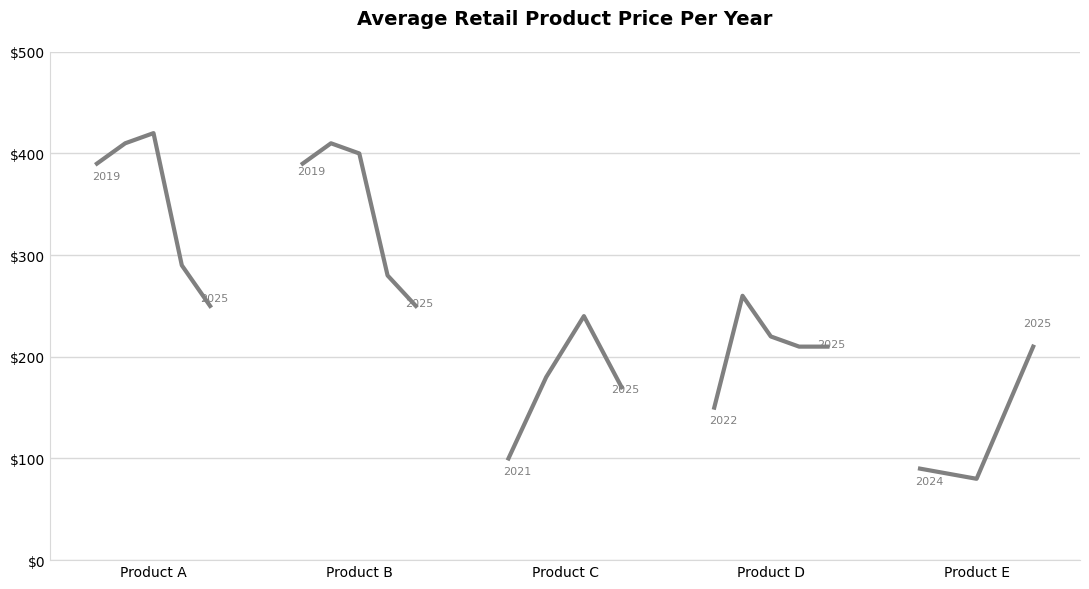

In [64]:
#Average Retail Product Price Per Year
import matplotlib.pyplot as plt
import numpy as np

#Products
products = ['Product A','Product B','Product C','Product D','Product E']

#Positions
x_positions = [1,3,5,7,9]

#Yearly Price
product_data = {
    'Product A': {
    'years': ['2019','','','','2025'],
    'prices': [390,410,420,290,250]
},
    'Product B': {
    'years': ['2019','','','','2025'],
    'prices': [390,410,400,280,250]
},
    'Product C': {
    'years': ['2021','','','2025'],
    'prices': [100,180,240,170]
},
    'Product D': {
    'years': ['2022','','','','2025'],
    'prices': [150,260,220,210,210]
},
    'Product E': {
    'years': ['2024','','2025'],
    'prices': [90,80,210]
    }
}

#Creat Plot
fig, ax = plt.subplots(figsize=(11,6))

for i, product in enumerate(products):
    data = product_data[product]

    #create the values around each product
    num_points = len(data['prices'])

    x= np.linspace(
        x_positions[i]-0.55,
        x_positions[i]+0.55,
        num_points
    )
    ax.plot(x,data['prices'],color='#808080',linewidth=3)

#Labels
ax.text(0.40,375,'2019',fontsize=8,color='gray')
ax.text(1.45,255,'2025',fontsize=8,color='gray')

ax.text(2.40,380,'2019',fontsize=8,color='gray')
ax.text(3.45,250,'2025',fontsize=8,color='gray')

ax.text(4.40,85,'2021',fontsize=8,color='gray')
ax.text(5.45,165,'2025',fontsize=8,color='gray')

ax.text(6.40,135,'2022',fontsize=8,color='gray')
ax.text(7.45,210,'2025',fontsize=8,color='gray')

ax.text(8.40,75,'2024',fontsize=8,color='gray')
ax.text(9.45,230,'2025',fontsize=8,color='gray')

#Title
ax.set_title('Average Retail Product Price Per Year', fontsize=14,fontweight='bold',pad=20)

#Axis
ax.set_xticks(x_positions)
ax.set_xticklabels(products)

#Y axis
ax.set_ylim(0,500)
ax.set_yticks([0,100,200,300,400,500])
ax.set_yticklabels(['$0','$100','$200','$300','$400','$500'])

ax.grid(axis='y',color='#d9d9d9',linewidth=1)

#Format Plot Area
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_color('#d9d9d9')
ax.spines['bottom'].set_color('#d9d9d9')

ax.tick_params(axis='both',length=0)

plt.tight_layout()
plt.show()
